# 7. Spreading of a droplet

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–3, 5 and 6

Put a small drop of silicone oil on a clean glass plate. It spreads, quickly at
first and then more and more slowly: after a second it is a lens a few
millimetres across, after an hour its radius has only doubled, and it is still
creeping outwards the next day. The radius grows as the tenth root of the time.
This is Tanner's law, and few results in soft matter have such a small exponent.

The exponent comes out of the recipe of the book with one slow variable, the radius
$R(t)$ of the wetted circle. The free energy is that of the interfaces, as in
Chapter 6. The dissipation function is new. The liquid flows in a film that
becomes thinner and thinner towards the edge of the drop, and the friction of such
a wedge is so large that it has to be cut off at a microscopic length. The cut-off
enters the result only through a logarithm.

The check is a numerical solution of the thin-film equation, which describes the
whole free surface with no assumption about its shape. It confirms the law and the
shape of the drop, and it shows which part of the answer a trial shape cannot give:
the number in front of the logarithm.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 7.1 The slow variable

A drop of volume $\Omega$ lies on a horizontal solid. The liquid has viscosity
$\eta$ and surface tension $\gamma$. The drop is small enough for gravity to be
neglected (Exercise 3 says how small) and it is already flat: the slope of its
surface is small everywhere. Let $h(r,t)$ be its thickness at the distance $r$
from the axis, and $R(t)$ the radius of the wetted circle.

*Why one variable is enough.* Inside the drop the liquid layer is thick and the
liquid moves easily, so that any difference of pressure between two points is
levelled out quickly. A uniform pressure means a uniform curvature of the free
surface: the drop is a spherical cap. Near the edge the layer is thin, the liquid
moves with difficulty, and the edge advances slowly. The shape therefore adjusts
to the position of the edge and not the other way round, and the position of the
edge is the slow variable. This is the reasoning of Chapter 5: a family of shapes,
and one parameter that carries the motion.

For small slopes a spherical cap is a paraboloid. With the volume fixed, the
family is

$$ h(r,t) = h_c\Big(1 - \frac{r^2}{R^2}\Big) , \qquad h_c = \frac{2\Omega}{\pi R^2} , \qquad \theta = -\frac{\partial h}{\partial r}\Big|_{r=R} = \frac{2h_c}{R} = \frac{4\Omega}{\pi R^3} . \tag{7.1} $$

Here $h_c$ is the thickness at the centre and $\theta$ the angle at which the cap
meets the solid, the *dynamic contact angle*. Both are fixed by $R$: as the drop
spreads it becomes thinner and its contact angle falls as $R^{-3}$. The constraint
of constant volume has been used by elimination.

## 7.2 The free energy

Three interfaces change when the drop spreads. The solid under the drop, of area
$\pi R^2$, exchanges its contact with vapour for a contact with liquid. The free
surface of the drop has the area $\int\sqrt{1 + (\partial h/\partial r)^2}\,dS
\approx \pi R^2 + \int\tfrac12(\partial h/\partial r)^2\,dS$ for small slopes.
Leaving out a constant,

$$ A = -S\,\pi R^2 + \gamma\int_0^R \frac12\Big(\frac{\partial h}{\partial r}\Big)^2\,2\pi r\,dr , \qquad S = \gamma_{SV} - \gamma_{SL} - \gamma . $$

$S$ is the *spreading coefficient*: the free energy gained per unit area when dry
solid is covered by a thick layer of liquid.

If $S < 0$ the liquid wets the solid partially. Young's law,
$\gamma_{SV} - \gamma_{SL} = \gamma\cos\theta_e$, defines the equilibrium contact angle
$\theta_e$, and $-S = \gamma(1 - \cos\theta_e) \approx \tfrac12\gamma\theta_e^2$ for a small
angle.

If $S \ge 0$ the liquid wets the solid completely and there is no equilibrium
angle. For $S > 0$ a film of molecular thickness, the *precursor film*, runs ahead
of the visible drop, and the excess $S$ is dissipated inside that film (de Gennes,
1985). The visible drop then spreads as it would for $S = 0$. This result is taken
as given here: complete wetting is the case $\theta_e = 0$.

With the profile (7.1) the integral is $\pi h_c^2$, and

$$ A(R) = \gamma\Big[\tfrac12\pi\theta_e^2R^2 + \frac{4\Omega^2}{\pi R^4}\Big] . \tag{7.2} $$

The first term is the cost of covering the solid, which grows with the wetted
area. The second is the excess area of the curved free surface, which falls as
the drop flattens. The force that drives the spreading is

$$ -\frac{\partial A}{\partial R} = 2\pi R\times\tfrac12\gamma\,(\theta^2 - \theta_e^2) , \tag{7.3} $$

with $\theta$ from Eq. (7.1). Its meaning is plain. At the edge the three
interfacial tensions pull on the contact line with the net force
$\gamma_{SV} - \gamma_{SL} - \gamma\cos\theta = \gamma(\cos\theta_e - \cos\theta)$ per unit
length, the unbalanced part of Young's law, and for small angles this is
$\tfrac12\gamma(\theta^2 - \theta_e^2)$. Equation (7.3) is that force times the length of
the line. The drop is in equilibrium when $\theta = \theta_e$, that is, at the radius

$$ R_e = \Big(\frac{4\Omega}{\pi\theta_e}\Big)^{1/3} . \tag{7.4} $$

## 7.3 The dissipation function

*Kinematics.* The drop is a thin film on a solid, so the first row of the second
table of Section 3.2 applies: the friction acts on the mean velocity $\bar v(r,t)$ of
the liquid across the film. That velocity is fixed by the conservation of volume,

$$ \frac{\partial h}{\partial t} + \frac{1}{r}\frac{\partial}{\partial r}\big(r\,h\,\bar v\big) = 0 . $$

For any family of the form $h = R^{-2}f(r/R)$ the solution is

$$ \bar v(r,t) = \frac{r}{R}\,\dot R , \tag{7.5} $$

which the cell below verifies. The liquid moves outwards with a velocity
proportional to the distance from the axis, and at the edge it moves with the
edge. The drop is stretched uniformly in its plane, like a rubber sheet.

*Dissipation.* The dissipation function is

$$ \Phi = \frac12\int \frac{3\eta}{h}\,\bar v^2\,2\pi r\,dr = \frac{3\pi\eta\,\dot R^2}{R^2}\int \frac{r^3}{h}\,dr . $$

Near the edge $h \approx \theta\,(R - r)$ and the integral diverges as
$\int dr/(R - r)$. A wedge of liquid cannot advance over a solid if the liquid
sticks to the solid everywhere: the friction would be infinite (Huh and Scriven,
1971). The divergence is only logarithmic, and it is removed by anything that
changes the picture at molecular distances: a precursor film, slip of the liquid
on the solid, or simply the size of the molecules. The simplest way to account
for this is to stop the integral where the film is as thin as a microscopic
length $b$, of the order of a nanometre, that is, at the distance $\epsilon = b/\theta$
from the edge. Then

$$ \int_0^{R-\epsilon}\frac{r^3}{h}\,dr = \frac{R^4}{2h_c}\Big[\ln\frac{h_c}{b} - 1\Big] , $$

up to terms that vanish with $b$, and

$$ \Phi = \frac{3\pi^2\eta\,\ell}{4\Omega}\,R^4\dot R^2 , \qquad \ell = \ln\frac{h_c}{b} - 1 . \tag{7.6} $$

The cell below does the two integrals and the check of Eq. (7.5).

In [2]:
r, R, Rdot, Om, gam, eta, the_e, xi, delta = sp.symbols("r R Rdot Omega gamma eta theta_e xi delta", positive=True)

h_cap = 2 * Om / (sp.pi * R**2) * (1 - r**2 / R**2)
v_bar = r * Rdot / R

# conservation of volume: dh/dt + (1/r) d(r h v)/dr = 0, with dh/dt = (dh/dR) Rdot
print("volume conservation:", sp.simplify(sp.diff(h_cap, R) * Rdot + sp.diff(r * h_cap * v_bar, r) / r))

# free energy (7.2)
A = gam * (sp.pi * the_e**2 * R**2 / 2 + sp.integrate(sp.Rational(1, 2) * sp.diff(h_cap, r) ** 2 * 2 * sp.pi * r, (r, 0, R)))
print("A =", sp.simplify(A))

# the integral of xi^3 / (1 - xi^2) up to 1 - delta, for small delta
integral = sp.integrate(xi**3 / (1 - xi**2), (xi, 0, 1 - delta))
print("integral =", sp.series(integral, delta, 0, 1))

volume conservation: 0
A = gamma*(8*Omega**2 + pi**2*R**6*theta_e**2)/(2*pi*R**4)
integral = -log(2)/2 - 1/2 - log(delta)/2 + O(delta)


The integral is $\tfrac12[\ln(1/2\delta) - 1]$ with $\delta = \epsilon/R = b/2h_c$,
which gives Eq. (7.6).

Three remarks.

First, $\ell$ is a large number that hardly changes. For a drop $0.1$ mm thick
and $b = 1$ nm, $\ell = \ln 10^5 - 1 \approx 10.5$; when the drop has thinned by a
factor of ten, $\ell \approx 8.2$. In a first reading $\ell$ can be taken as a
constant of the order of ten.

Second, in terms of the contact angle, Eq. (7.6) reads

$$ \Phi = \frac12\,\xi_{\rm hyd}\,\dot R^2\times 2\pi R , \qquad \xi_{\rm hyd} = \frac{3\eta\,\ell}{\theta} . \tag{7.7} $$

This is the last row of the first table of Section 3.2: a friction on the moving
contact line. The friction constant is not a property of the materials alone. It
is the viscous friction of the wedge of liquid behind the line, and it grows
without limit as the wedge becomes sharper.

Third, the dissipation is not concentrated at the edge in the usual sense. Each
factor of ten in the distance from the contact line contributes the same amount,
from the molecular scale up to the size of the drop. Panel (b) of Figure 7.1
shows this.

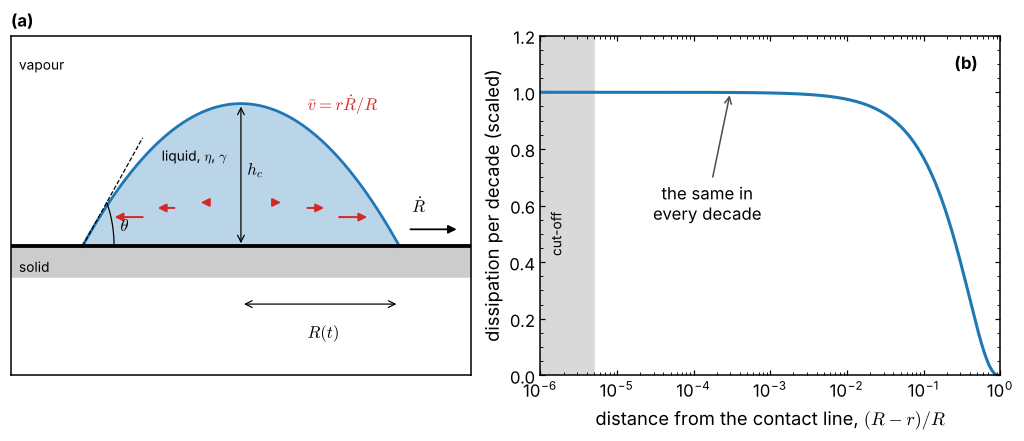

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

# (a) schematic of the drop (the thickness is exaggerated)
x = np.linspace(-1, 1, 400)
cap = 0.42 * (1 - x**2)
ax1.fill_between(x, 0, cap, color="C0", alpha=0.3)
ax1.plot(x, cap, color="C0", lw=1.8)
ax1.plot([-1.45, 1.45], [0, 0], "k-", lw=2.5)
ax1.fill_between([-1.45, 1.45], -0.09, 0, color="0.8")
for x0 in (0.2, 0.4, 0.6):
    for sgn in (1, -1):
        y0 = 0.42 * (1 - x0**2) * 0.32
        ax1.annotate("", xy=(sgn * (x0 + 0.36 * x0), y0), xytext=(sgn * x0, y0),
                     arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.3))
ax1.annotate("", xy=(0, 0.42), xytext=(0, 0), arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
ax1.text(0.04, 0.21, "$h_c$")
ax1.annotate("", xy=(1, -0.17), xytext=(0, -0.17), arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
ax1.text(0.42, -0.27, "$R(t)$")
ax1.plot([-1, -1 + 0.38], [0, 0.38 * 0.84], "k--", lw=0.8)
arc = np.linspace(0, math.atan(0.84), 30)
ax1.plot(-1 + 0.2 * np.cos(arc), 0.2 * np.sin(arc), "k-", lw=0.8)
ax1.text(-0.76, 0.045, r"$\theta$")
ax1.annotate("", xy=(1.38, 0.05), xytext=(1.05, 0.05), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.2))
ax1.text(1.08, 0.1, r"$\dot R$")
ax1.text(0.42, 0.4, r"$\bar v = r\dot R/R$", color="C3")
ax1.text(-1.4, 0.52, r"vapour", fontsize=9)
ax1.text(-0.5, 0.25, r"liquid, $\eta$, $\gamma$", fontsize=9)
ax1.text(-1.4, -0.075, "solid", fontsize=9)
ax1.set_xlim(-1.45, 1.45); ax1.set_ylim(-0.38, 0.62); ax1.set_xticks([]); ax1.set_yticks([])
ax1.set_title("(a)", loc="left", fontweight="bold")

# (b) dissipation per decade of distance from the contact line
s = np.logspace(-6, 0, 400)               # s = (R - r)/R
xi_ = 1 - s
per_decade = xi_**3 * s / (1 - xi_**2)    # integrand of (7.6) times (R - r)
ax2.semilogx(s, per_decade / 0.5, color="C0", lw=2)
ax2.axvspan(1e-6, 5e-6, color="0.85")
ax2.text(1.25e-6, 0.5, "cut-off", rotation=90, va="center", fontsize=9)
ax2.annotate("the same in\nevery decade", xy=(3e-4, 1.0), xytext=(1.5e-4, 0.55), ha="center",
             arrowprops=dict(arrowstyle="->", color="0.3"))
ax2.set_xlabel(r"distance from the contact line, $(R - r)/R$")
ax2.set_ylabel("dissipation per decade (scaled)")
ax2.set_xlim(1e-6, 1); ax2.set_ylim(0, 1.2)
on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure 7.1.** **(a)** The drop (the thickness is exaggerated). The free surface is
a cap that meets the solid at the dynamic contact angle $\theta$; the liquid is
stretched uniformly, with a mean velocity proportional to the distance from the
axis. **(b)** Where the energy is dissipated. The curve is the integrand of
Eq. (7.6) per decade of distance from the contact line, in units of its value at
the edge. It is flat over all the decades between the size of the drop and the
microscopic cut-off (grey band, drawn for $h_c = 0.1$ mm and $b = 1$ nm): every
scale contributes equally, and their number is the logarithm $\ell$.

## 7.4 Minimise: Tanner's law

The Rayleighian is $\Phi + \dot A$ with $\dot A = (\partial A/\partial R)\,\dot R$.
Minimising with respect to $\dot R$ and using Eqs. (7.3) and (7.7),

$$ \frac{3\eta\,\ell}{\theta}\,\dot R = \tfrac12\gamma\,(\theta^2 - \theta_e^2) \qquad\Longrightarrow\qquad \dot R = \frac{\gamma}{6\eta\,\ell}\;\theta\,(\theta^2 - \theta_e^2) . \tag{7.8} $$

The friction of the wedge balances the unbalanced Young force. This relation
between the speed of a contact line and the dynamic contact angle was obtained in
this way, from the dissipation in a wedge, by de Gennes (1985). The cell below
obtains it from the two functions (7.2) and (7.6).

In [4]:
ell = sp.symbols("ell", positive=True)
Phi = 3 * sp.pi**2 * eta * ell * R**4 * Rdot**2 / (4 * Om)

kinetic = on.kinetic_equations(A, Phi, [R], [Rdot])
print("Rdot =", sp.factor(kinetic[Rdot]))

theta = 4 * Om / (sp.pi * R**3)
print("difference from Eq. (7.8):", sp.simplify(kinetic[Rdot] - gam * theta * (theta**2 - the_e**2) / (6 * eta * ell)))

Rdot = 2*Omega*gamma*(4*Omega - pi*R**3*theta_e)*(4*Omega + pi*R**3*theta_e)/(3*pi**3*R**9*ell*eta)
difference from Eq. (7.8): 0


**Complete wetting.** With $\theta_e = 0$ and $\theta = 4\Omega/\pi R^3$,

$$ \dot R = \frac{32\,\gamma\,\Omega^3}{3\pi^3\eta\,\ell}\,\frac{1}{R^9} , \qquad R^{10} = R_0^{10} + \frac{320\,\gamma\,\Omega^3}{3\pi^3\eta\,\ell}\;t , \tag{7.9} $$

where the second form treats $\ell$ as a constant. At long times

$$ R \simeq \Big(\frac{320}{3\pi^3\ell}\Big)^{1/10}\,\Omega^{3/10}\Big(\frac{\gamma\,t}{\eta}\Big)^{1/10} , \qquad \theta \propto t^{-3/10} . \tag{7.10} $$

This is Tanner's law (Tanner, 1979). Three features deserve a comment.

*The exponent.* The driving force is proportional to $\theta^2$ and the friction to
$1/\theta$, so the speed goes as $\theta^3 \propto R^{-9}$. The tenth root is the result
of a force that fades and a friction that grows as the drop flattens.

*The dependence on the liquid.* The surface tension and the viscosity enter only
through the velocity $\gamma/\eta$, raised to the power $1/10$. A liquid a thousand
times more viscous makes a drop only half as wide after the same time. The radius
is set almost entirely by the volume.

*The spreading coefficient is absent.* A liquid with a large $S$ does not spread
faster than one with $S = 0$, since the excess is spent in the precursor film.

**Partial wetting.** With $\theta_e > 0$ the right-hand side of Eq. (7.8) vanishes
at $\theta = \theta_e$. The drop follows Tanner's law while $\theta \gg \theta_e$ and
then settles at the radius $R_e$ of Eq. (7.4); a drop that starts too wide
retracts. The approach to $R_e$ is exponential (Exercise 2).

The cell below integrates Eq. (7.8), with the logarithm $\ell$ of Eq. (7.6)
evaluated along the way, first in scaled form and then for drops of a silicone
oil.

In [5]:
def spreading(t, R_start, volume, speed, b, theta_e=0.0):
    """R(t) from Eq. (7.8). speed = gamma/eta; all quantities in one system of units."""
    def rate(t, R):
        theta = 4 * volume / (np.pi * R[0] ** 3)
        ell = np.log(2 * volume / (np.pi * R[0] ** 2 * b)) - 1
        return [speed * theta * (theta**2 - theta_e**2) / (6 * ell)]
    sol = solve_ivp(rate, (0, t[-1]), [R_start], t_eval=t, rtol=1e-10, atol=1e-14)
    return sol.y[0]

# a silicone oil: viscosity 1 Pa s, surface tension 0.021 N/m, density 970 kg/m^3
gamma_oil, eta_oil, rho_oil, b_oil = 0.021, 1.0, 970.0, 1e-9
t_s = np.concatenate(([0.0], np.logspace(-2, 5, 141)))
drops = {}
for volume_mm3 in (0.1, 1.0, 10.0):
    volume = volume_mm3 * 1e-9
    R_start = (4 * volume / (np.pi * 0.5)) ** (1 / 3)        # start at a contact angle of 0.5 rad
    drops[volume_mm3] = spreading(t_s, R_start, volume, gamma_oil / eta_oil, b_oil)

print("radius in mm of a drop of silicone oil (1 Pa s) after")
print("  volume     1 s    1 min     1 h    1 day")
for volume_mm3, R_t in drops.items():
    row = [np.interp(tt, t_s, R_t) * 1e3 for tt in (1, 60, 3600, 86400)]
    print(f"  {volume_mm3:4.1f} mm3 " + "".join(f"{x:7.2f} " for x in row))
slope, _ = on.loglog_slope(t_s[1:], drops[1.0][1:], fit_range=(1e2, 1e5))
print(f"fitted exponent between 100 s and 1 day (1 mm3): {slope:.4f}")
capillary_length = math.sqrt(gamma_oil / (rho_oil * 9.81))
print(f"capillary length {capillary_length*1e3:.2f} mm; gravity takes over near R = {2*math.sqrt(3)*capillary_length*1e3:.1f} mm (Exercise 3)")

radius in mm of a drop of silicone oil (1 Pa s) after
  volume     1 s    1 min     1 h    1 day
   0.1 mm3    0.67    0.92    1.39    1.92 
   1.0 mm3    1.40    1.82    2.75    3.80 
  10.0 mm3    2.98    3.63    5.44    7.52 
fitted exponent between 100 s and 1 day (1 mm3): 0.1016
capillary length 1.49 mm; gravity takes over near R = 5.1 mm (Exercise 3)


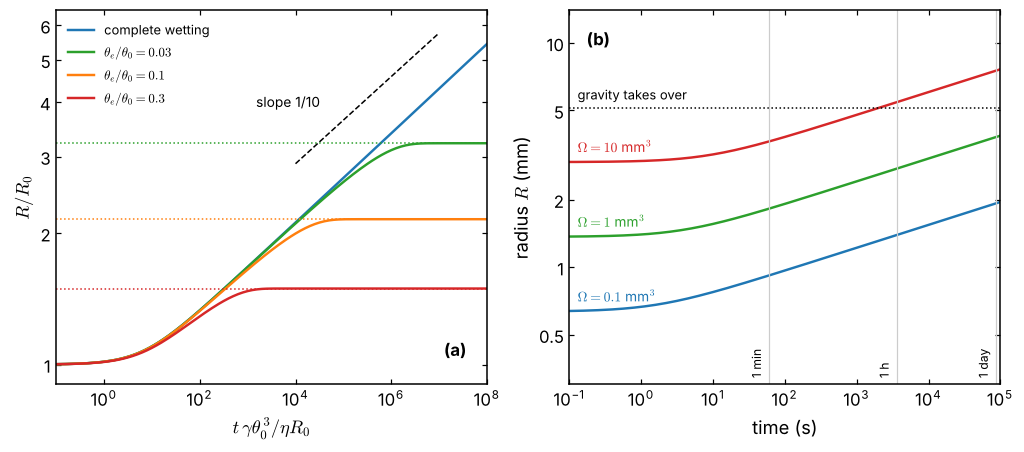

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.0))

# (a) scaled: R/R_0 against t gamma theta_0^3 / (eta R_0), complete and partial wetting
t_sc = np.concatenate(([0.0], np.logspace(-2, 8, 201)))
volume_sc = np.pi / 4                          # R_0 = 1 and theta_0 = 1
for ratio, color in ((0.0, "C0"), (0.03, "C2"), (0.1, "C1"), (0.3, "C3")):
    R_sc = spreading(t_sc, 1.0, volume_sc, 1.0, 5e-6, theta_e=ratio)
    label = "complete wetting" if ratio == 0 else rf"$\theta_e/\theta_0 = {ratio}$"
    ax1.loglog(t_sc[1:], R_sc[1:], color=color, label=label)
    if ratio > 0:
        ax1.axhline(ratio ** (-1 / 3), color=color, ls=":", lw=1)
tt = np.array([1e4, 1e7])
ax1.loglog(tt, 1.15 * tt**0.1, "k--", lw=1)
ax1.text(1.5e3, 3.9, "slope 1/10", fontsize=9)
ax1.set_xlabel(r"$t\,\gamma\theta_0^3/\eta R_0$"); ax1.set_ylabel(r"$R/R_0$")
ax1.set_xlim(1e-1, 1e8); ax1.set_ylim(0.9, 6.5)
ax1.set_yticks([1, 2, 3, 4, 5, 6]); ax1.set_yticklabels(["1", "2", "3", "4", "5", "6"]); ax1.minorticks_off()
ax1.legend(loc="upper left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.9, y=0.12)

# (b) silicone oil, real units
for (volume_mm3, R_t), color in zip(drops.items(), ("C0", "C2", "C3")):
    ax2.loglog(t_s[1:], R_t[1:] * 1e3, color=color)
    ax2.text(0.13, R_t[1] * 1e3 * 1.1, rf"$\Omega = {volume_mm3:g}$ mm$^3$", color=color, fontsize=9)
ax2.axhline(2 * math.sqrt(3) * capillary_length * 1e3, color="k", ls=":", lw=1)
ax2.text(0.13, 5.6, "gravity takes over", fontsize=8.5)
for tt_, name in ((60, "1 min"), (3600, "1 h"), (86400, "1 day")):
    ax2.axvline(tt_, color="0.8", lw=0.8); ax2.text(tt_ * 0.85, 0.33, name, fontsize=8, rotation=90, ha="right")
ax2.set_xlabel("time (s)"); ax2.set_ylabel("radius $R$ (mm)")
ax2.set_xlim(1e-1, 1e5); ax2.set_ylim(0.3, 14)
ax2.set_yticks([0.5, 1, 2, 5, 10]); ax2.set_yticklabels(["0.5", "1", "2", "5", "10"]); ax2.minorticks_off()
on.panel_label(ax2, "(b)", x=0.04, y=0.95)
plt.show()

**Figure 7.2.** **(a)** Radius of the drop from Eq. (7.8), starting from the radius
$R_0$ and the contact angle $\theta_0$, with $h_c/b = 10^5$ at the start. For complete
wetting the curve approaches a straight line of slope $1/10$. For partial
wetting the drop stops at the radius $R_e = R_0(\theta_0/\theta_e)^{1/3}$ (dotted
lines). **(b)** The same law for three drops of a silicone oil of viscosity
1 Pa s. A thousandfold increase in time widens the drop by a factor of two. The
dotted line is the radius at which gravity becomes the main driving force.

## 7.5 Check: the thin-film equation

The kinetic equation (7.8) rests on a trial shape. To test it we need the motion of
the whole free surface. That is a field problem of the kind treated in
Chapter 4, and the same principle gives its equation.

*Variables and constraint.* The field $h(\mathbf r,t)$ on the plane of the solid,
and the mean velocity $\bar{\mathbf v}(\mathbf r,t)$, linked by
$\partial h/\partial t = -\nabla\cdot(h\bar{\mathbf v})$.

*The two functions.* Away from the edge of the drop,

$$ A[h] = \gamma\int\tfrac12\lvert\nabla h\rvert^2\,dS , \qquad \Phi[\bar{\mathbf v}] = \frac12\int\frac{3\eta}{h}\,\bar{\mathbf v}^2\,dS . $$

*Minimise.* Integrating by parts twice,
$\dot A = -\gamma\int\nabla^2h\,(\partial h/\partial t)\,dS = -\gamma\int h\,\bar{\mathbf v}\cdot\nabla(\nabla^2 h)\,dS$,
and setting the functional derivative of $\Phi + \dot A$ with respect to
$\bar{\mathbf v}$ to zero gives $\bar{\mathbf v} = (\gamma h^2/3\eta)\,\nabla\nabla^2h$. The liquid is
driven by the gradient of the capillary pressure $-\gamma\nabla^2h$. Inserting this
in the constraint,

$$ \frac{\partial h}{\partial t} = -\frac{\gamma}{3\eta}\,\nabla\cdot\big(h^3\,\nabla\nabla^2 h\big) . \tag{7.11} $$

This is the thin-film equation. It contains the same physics as Eq. (7.8) and no
assumption about the shape.

*The contact line.* Equation (7.11) has the same divergence at a contact line as
the integral of Section 7.3, and it needs the same cure. In the numerical solution
the solid is covered everywhere by a precursor film of thickness $b$, so that
there is no line at which $h$ vanishes. For complete wetting nothing else is
needed. For partial wetting a disjoining pressure
$\Pi(h) \propto \theta_e^2\,[(b/h)^3 - (b/h)^2]$ is added to the capillary pressure;
it makes the film of thickness $b$ stable and gives the drop the equilibrium angle
$\theta_e$ (Schwartz and Eley, 1998). The function `on.thin_film_fv` solves the
equation by finite volumes, so that the volume is conserved to rounding error.

*Units.* Lengths along the solid are measured in units of the initial radius
$R_0$, thicknesses in units of the initial thickness $h_{c0}$ and times in units
of $3\eta R_0^4/\gamma h_{c0}^3$. Slopes are then in units of $h_{c0}/R_0$. In these
units $\Omega = \pi/2$, $h_c = 1/R^2$, $\theta = 2/R^3$, and Eq. (7.8) reads

$$ \frac{dR}{dt} = \frac{\theta\,(\theta^2 - \theta_e^2)}{2\,\ell} , \qquad \ell = \ln\frac{h_c}{b} - 1 . \tag{7.12} $$

The cut-off of the variational calculation is identified with the thickness of
the precursor film. A computation cannot reach the ratio $h_c/b \sim 10^5$ of a
real drop, because the grid must resolve the film; the runs below use
$b = 10^{-2}$, $3\times10^{-3}$ and $10^{-3}$.

*What is compared.* The radius of the numerical drop is measured in the way an
experiment would measure it. A parabola is fitted to the central half of the
profile (`on.fit_cap`); the point where it meets the solid is the apparent
radius $R$, and its slope there is the apparent contact angle $\theta = 2h_c/R$.

In [7]:
times = np.concatenate(([0.0], np.logspace(-2, 3, 101)))

def thin_film_drop(b, n, length, theta_e=0.0):
    """Spread the cap h = 1 - r^2 on a precursor film b; returns r, h, h_c(t), R(t)."""
    edges = np.linspace(0.0, length, n + 1)
    rc = 0.5 * (edges[1:] + edges[:-1])
    rc, h = on.thin_film_fv(np.maximum(1 - rc**2, 0.0) + b, edges, times, theta_e=theta_e, b=b)
    fit = np.array([on.fit_cap(rc, hk, b=b) for hk in h])
    volume = 2 * np.pi * np.sum((h - b) * rc, axis=1) * (edges[1] - edges[0])
    return dict(r=rc, h=h, hc=fit[:, 0], R=fit[:, 1], b=b, theta_e=theta_e, volume=volume)

def variational_drop(run, start=41):
    """Eq. (7.12) from the numerical radius at times[start] (t = 1) onwards."""
    b, theta_e = run["b"], run["theta_e"]
    def rate(t, R):
        theta = 2 / R[0] ** 3
        return [theta * (theta**2 - theta_e**2) / (2 * (np.log(1 / (R[0] ** 2 * b)) - 1))]
    sol = solve_ivp(rate, (times[start], times[-1]), [run["R"][start]], t_eval=times[start:], rtol=1e-10, atol=1e-13)
    return sol.y[0]

runs = [thin_film_drop(1e-2, 850, 3.4), thin_film_drop(3e-3, 1600, 3.2), thin_film_drop(1e-3, 3750, 3.0)]
partial = thin_film_drop(2e-3, 2400, 2.4, theta_e=0.6)

print("complete wetting, t from 1 to 1000")
print("     b     volume drift   R(1000)   Eq. (7.12)   largest difference   exponent for t > 30: thin film, Eq. (7.12)")
for run in runs:
    run["R_var"] = variational_drop(run)
    gap = np.max(np.abs(run["R_var"] / run["R"][41:] - 1))
    slope, _ = on.loglog_slope(times, run["R"], fit_range=(30, 1000))
    slope_var, _ = on.loglog_slope(times[41:], run["R_var"], fit_range=(30, 1000))
    print(f"  {run['b']:6.3f}    {np.ptp(run['volume']):.1e}     {run['R'][-1]:.4f}     {run['R_var'][-1]:.4f}         {100*gap:5.2f} %                     {slope:.4f}      {slope_var:.4f}")

partial["R_var"] = variational_drop(partial)
R_e = (2 / 0.6) ** (1 / 3)
print(f"\npartial wetting, theta_e = 0.6:  final radius {partial['R'][-1]:.4f},  Eq. (7.4) {R_e:.4f},"
      f"  final angle {2*partial['hc'][-1]/partial['R'][-1]:.4f}")
print(f"largest difference in R between Eq. (7.12) and the thin-film equation: {100*np.max(np.abs(partial['R_var']/partial['R'][41:] - 1)):.2f} %")

complete wetting, t from 1 to 1000
     b     volume drift   R(1000)   Eq. (7.12)   largest difference   exponent for t > 30: thin film, Eq. (7.12)
   0.010    5.1e-14     2.6860     2.7201          1.32 %                     0.1104      0.1102
   0.003    1.8e-14     2.5369     2.5753          1.65 %                     0.1066      0.1062
   0.001    1.4e-14     2.4504     2.4950          1.93 %                     0.1049      0.1046

partial wetting, theta_e = 0.6:  final radius 1.5014,  Eq. (7.4) 1.4938,  final angle 0.5885
largest difference in R between Eq. (7.12) and the thin-film equation: 0.57 %


Four things can be read from the output.

*The volume* is conserved to rounding error, as it must be for a scheme written in
terms of fluxes.

*The radius.* Over three decades of time, in which the contact angle falls by a
factor of about nine, the radius from Eq. (7.12) stays within 2 % of the radius from the
thin-film equation, for each of the three films.

*The exponent.* The fitted exponents, 0.110, 0.107 and 0.105, lie a little above
$1/10$ and come closer to it as the film becomes thinner. This is the logarithm:
$\ell$ falls slowly as the drop flattens, so the friction grows slightly less
quickly than $1/\theta$. Equation (7.12) contains this effect and gives nearly the
same exponents. A fit to an experiment over a few decades of time gives the same
kind of number, and for a real drop, with its much larger logarithm, the
difference from $1/10$ is smaller still.

*Partial wetting.* The drop stops at a radius 0.5 % above $R_e$ of Eq. (7.4), and
its approach to that radius is followed to better than 1 %. The small excess is
an effect of the film of finite thickness and shrinks with $b$.

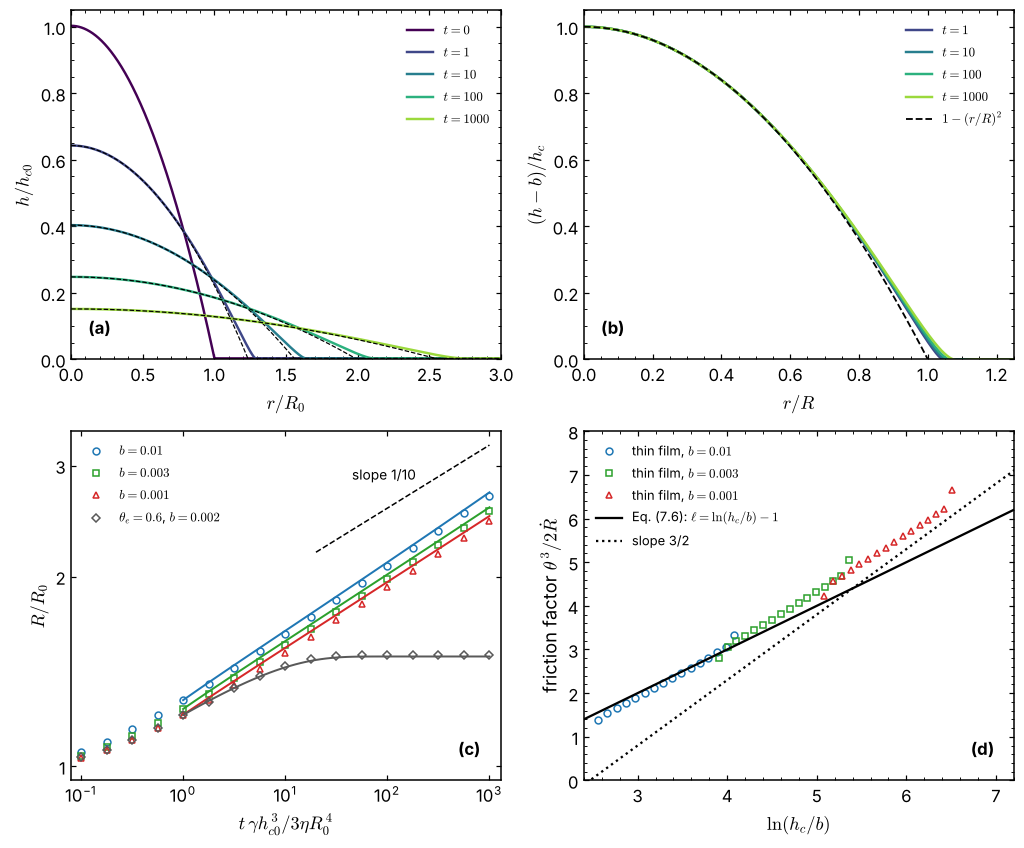

slope of the measured friction factor for 2.8 < ln(h_c/b) < 4.2: 1.16
slope of the measured friction factor for 5.2 < ln(h_c/b) < 6.6: 1.35
measured / Eq. (7.6): from 0.90 to 1.21
extrapolated to h_c/b = 1e5: friction factor about 14.2, Eq. (7.6) gives 10.5; ratio 1.35, ratio of the radii 0.971


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
mid = runs[1]                                     # b = 0.003
shown = [0, 41, 61, 81, 101]                      # t = 0, 1, 10, 100, 1000
colors = plt.cm.viridis(np.linspace(0.0, 0.85, len(shown)))

ax = axes[0, 0]
for k, color in zip(shown, colors):
    ax.plot(mid["r"], mid["h"][k], color=color, label=f"$t = {times[k]:g}$")
    if k > 0:
        ax.plot(mid["r"], np.maximum(mid["hc"][k] * (1 - mid["r"] ** 2 / mid["R"][k] ** 2), 0) + mid["b"], "k--", lw=0.8)
ax.set_xlabel("$r/R_0$"); ax.set_ylabel("$h/h_{c0}$")
ax.set_xlim(0, 3); ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.12)

ax = axes[0, 1]
for k, color in zip(shown[1:], colors[1:]):
    ax.plot(mid["r"] / mid["R"][k], (mid["h"][k] - mid["b"]) / mid["hc"][k], color=color, label=f"$t = {times[k]:g}$")
xi_ = np.linspace(0, 1, 200)
ax.plot(xi_, 1 - xi_**2, "k--", lw=1.2, label=r"$1 - (r/R)^2$")
ax.set_xlabel("$r/R$"); ax.set_ylabel("$(h - b)/h_c$")
ax.set_xlim(0, 1.25); ax.set_ylim(0, 1.05)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.04, y=0.12)

ax = axes[1, 0]
for run, color, marker in zip(runs, ("C0", "C2", "C3"), ("o", "s", "^")):
    ax.loglog(times[21::5], run["R"][21::5], marker, color=color, mfc="none", ms=4.5, label=f"$b = {run['b']:g}$")
    ax.loglog(times[41:], run["R_var"], "-", color=color, lw=1.3)
ax.loglog(times[21::5], partial["R"][21::5], "D", color="0.35", mfc="none", ms=4, label=r"$\theta_e = 0.6$, $b = 0.002$")
ax.loglog(times[41:], partial["R_var"], "-", color="0.35", lw=1.3)
tt = np.array([20.0, 1000.0])
ax.loglog(tt, 1.62 * tt**0.1, "k--", lw=1); ax.text(45, 2.85, "slope 1/10", fontsize=9)
ax.set_xlabel(r"$t\,\gamma h_{c0}^3/3\eta R_0^4$"); ax.set_ylabel("$R/R_0$")
ax.set_xlim(0.08, 1300); ax.set_ylim(0.95, 3.4)
ax.set_yticks([1, 2, 3]); ax.set_yticklabels(["1", "2", "3"]); ax.minorticks_off()
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(c)", x=0.9, y=0.12)

ax = axes[1, 1]
for run, color, marker in zip(runs, ("C0", "C2", "C3"), ("o", "s", "^")):
    theta_app = 2 * run["hc"] / run["R"]
    K = theta_app[41:] ** 3 / (2 * np.gradient(run["R"][41:], times[41:]))
    run["logs"], run["K"] = np.log(run["hc"][41:] / run["b"]), K
    ax.plot(run["logs"][::4], K[::4], marker, color=color, mfc="none", ms=4.5, label=f"thin film, $b = {run['b']:g}$")
L_ = np.linspace(1.5, 7.5, 10)
ax.plot(L_, L_ - 1, "k-", lw=1.5, label=r"Eq. (7.6): $\ell = \ln(h_c/b) - 1$")
ax.plot(L_, 1.5 * L_ - 3.7, "k:", lw=1.5, label="slope 3/2")
ax.set_xlabel(r"$\ln(h_c/b)$"); ax.set_ylabel(r"friction factor $\theta^3/2\dot R$")
ax.set_xlim(2.4, 7.2); ax.set_ylim(0, 8)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.12)
plt.show()

both = np.concatenate([run["logs"] for run in runs]), np.concatenate([run["K"] for run in runs])
for lo, hi in ((2.8, 4.2), (5.2, 6.6)):
    keep = (both[0] > lo) & (both[0] < hi)
    print(f"slope of the measured friction factor for {lo} < ln(h_c/b) < {hi}: {np.polyfit(both[0][keep], both[1][keep], 1)[0]:.2f}")
print("measured / Eq. (7.6): from", f"{min((run['K']/(run['logs']-1)).min() for run in runs):.2f}", "to",
      f"{max((run['K']/(run['logs']-1)).max() for run in runs):.2f}")

# a real drop: h_c / b = 1e5.  Continue the measured curve with the slope 3/2 of the exact theory.
top = np.argmax(both[0])
K_real = both[1][top] + 1.5 * (np.log(1e5) - both[0][top])
ell_real = np.log(1e5) - 1
print(f"extrapolated to h_c/b = 1e5: friction factor about {K_real:.1f}, Eq. (7.6) gives {ell_real:.1f};"
      f" ratio {K_real/ell_real:.2f}, ratio of the radii {(K_real/ell_real)**-0.1:.3f}")

**Figure 7.3.** Check against the thin-film equation (7.11). **(a)** Profiles of a
spreading drop on a precursor film of thickness $b = 0.003$ (complete wetting).
The dashed lines are the caps fitted to the central half of each profile.
**(b)** The same profiles in units of the fitted height and radius. They fall on
the parabola of Eq. (7.1) except in the outer tenth, where the real surface bends
and reaches about 5 % beyond the apparent radius. **(c)** Radius against time:
thin-film equation (symbols) and Eq. (7.12) started from the numerical radius at
$t = 1$ (lines), for three films and for a partially wetting drop. **(d)** The
friction factor $\theta^3/2\dot R$ measured from the three runs, against the
logarithm of the ratio of scales. The runs fall on one curve. The variational
result is the full line; the dotted line shows the slope $3/2$ of the exact
theory for a large ratio of scales.

## 7.6 What the trial shape cannot give

The agreement in panel (c) is a weak test, and it is worth seeing why. By
Eq. (7.9) the radius depends on the friction through its tenth root: a friction
wrong by 50 % changes the radius by 4 %. Almost any estimate of the dissipation
gives a good radius.

Panel (d) tests the friction itself. In the units of Section 7.5, Eq. (7.12)
says that the combination $\theta^3/2\dot R$ is equal to $\ell = \ln(h_c/b) - 1$. Two
things are seen.

The three runs fall on a single curve. The friction is a function of the ratio of
the two scales, $h_c/b$, and of nothing else, and it grows as the logarithm of
that ratio. This is the structure of Eq. (7.6), and the count of decades in
Figure 7.1(b) is confirmed.

The slope of the curve is not 1. It is 1.2 at the lower end and 1.35 at the upper
end, and still rising. Over the range of the computation the measured friction
lies between 0.90 and 1.21 times the variational one. The agreement is closest
where the two lines cross, and is in part an accident of the constant $-1$.

The reason for the slope is known. Near a moving contact line the free surface
is not a straight wedge. The balance of viscous and capillary stresses makes
its slope at the distance $x$ from the line vary as

$$ \theta(x)^3 = \theta_m^3 + \frac{9\,\eta\,\dot R}{\gamma}\,\ln\frac{x}{b} , \tag{7.13} $$

where $\theta_m$ is the angle at the microscopic scale (Voinov, 1976; Cox, 1986).
The surface is curved over all the decades of Figure 7.1(b): the closer to the
line, the smaller the slope. A film that is thinner than the straight wedge has
more friction. For a drop that wets completely ($\theta_m = 0$) and a large ratio
of scales, Eq. (7.13) gives $\theta^3 = 9\,(\eta\dot R/\gamma)\ln(\ldots)$ where the wedge of
Eq. (7.8) gives $\theta^3 = 6\,(\eta\dot R/\gamma)\,\ell$: a slope of $3/2$ in panel (d)
in place of 1. The profiles of panel (b) show the bending directly.

The trial family (7.1) has no freedom to bend near the edge, so the variational
calculation cannot find this. It gives the best cap, and the best cap has the
right logarithm with the wrong number in front. For a real drop, with
$h_c/b = 10^5$, continuing the measured curve with the slope $3/2$ gives a friction
about a third larger than Eq. (7.6), and a radius about 3 % smaller than Eq. (7.9).

This is the lesson of Section 5.6 in a new setting. What to trust in the result
of this chapter:

* the exponents, $R \propto t^{1/10}$ and $\theta \propto t^{-3/10}$, and the dependence
  on the volume, the viscosity and the surface tension in Eq. (7.10);
* the form of the law of motion of a contact line, Eq. (7.8): an unbalanced
  Young force against a friction proportional to $\eta/\theta$ and to the logarithm of
  a ratio of scales;
* the radius itself, to a few per cent.

What not to trust is the coefficient of the logarithm, and with it the speed of
spreading to better than about a third. In practice the logarithm is a fitted
quantity in any case, because the microscopic length $b$ is not known
independently.

## Summary

* A small drop on a solid is a spherical cap whose radius $R$ is the one slow
  variable; the volume fixes its height and its contact angle, $\theta = 4\Omega/\pi R^3$.
* The free energy is that of the three interfaces. Its derivative is the
  unbalanced Young force, $\tfrac12\gamma(\theta^2 - \theta_e^2)$ per unit length of the
  contact line.
* The dissipation is that of a thin film stretched uniformly. It diverges
  logarithmically at the edge and is cut off at a microscopic thickness $b$;
  every decade of distance from the contact line dissipates the same amount.
  The result is a friction on the contact line, $\xi_{\rm hyd} = 3\eta\ell/\theta$ with
  $\ell = \ln(h_c/b) - 1$.
* Minimising the Rayleighian gives $\dot R = (\gamma/6\eta\ell)\,\theta(\theta^2 - \theta_e^2)$.
  For complete wetting this is Tanner's law, $R \propto \Omega^{3/10}(\gamma t/\eta)^{1/10}$;
  for partial wetting the drop stops at $R_e = (4\Omega/\pi\theta_e)^{1/3}$.
* The thin-film equation follows from the same two functions with the whole
  profile as the variable. Its numerical solution confirms the shape, the law
  and the radius to 2 %, and shows that the exact coefficient of the logarithm
  is $9$ where the cap gives $6$.

## Exercises

Sample solutions are in [`solutions/part2_liquids_interfaces/07_solutions.ipynb`](../../solutions/part2_liquids_interfaces/07_solutions.ipynb).

1. **A liquid ridge.** A long straight ridge of liquid has the cross-section
   $h = h_c(1 - x^2/R^2)$, of area $\Omega$, and the half-width $R(t)$. Per unit
   length of the ridge, show that $\theta = 3\Omega/2R^2$,
   $A = \gamma\,[\theta_e^2R + 3\Omega^2/4R^3]$ and
   $\Phi = (3\eta\ell_2/\theta)\,\dot R^2$ with $\ell_2 = \ln(4h_c/b) - 2$. Show that
   Eq. (7.8) holds unchanged with $\ell_2$ in place of $\ell$, and that a ridge
   which wets completely widens as $t^{1/7}$. Compare with
   `on.thin_film_fv(..., geometry="planar")`.
2. **The approach to equilibrium.** Linearise Eq. (7.8) about the radius $R_e$
   and show that $R - R_e \propto e^{-t/\tau}$ with $\tau = \eta\,\ell R_e/\gamma\theta_e^3$.
   Evaluate $\tau$ for $R_e = 1$ mm and $\theta_e = 0.3$, for the silicone oil of
   Section 7.4 and for water, and compare with a numerical solution of Eq. (7.8)
   for a drop that starts too narrow and one that starts too wide. Why is the
   relaxation so slow when $\theta_e$ is small?
3. **Heavy drops.** (a) Add the gravitational energy of the cap (7.1) to
   Eq. (7.2). Show that it is $2\rho g\Omega^2/3\pi R^2$, that gravity drives the
   spreading more strongly than the surface tension when $R > 2\sqrt3\,(\gamma/\rho g)^{1/2}$,
   and that the radius then grows as $t^{1/8}$. (b) A drop much wider than this is
   not a cap. Its profile is $h = h_c(1 - r^2/R^2)^{1/3}$ (Huppert, 1982). Repeat
   the calculation for this family with the gravitational energy alone. Why is
   no cut-off needed? Show that $R^8 = (2^{10}/3^5\pi^3)\,(\rho g\Omega^3/\eta)\,t$, which
   is the exact result, and explain why the variational calculation is exact
   here.
4. **Friction at the contact line.** Suppose that the contact line has a
   friction of its own, $\Phi_{\rm cl} = \tfrac12\xi_{\rm cl}\dot R^2\times 2\pi R$ (Section 3.2),
   in addition to the friction of the wedge. For complete wetting, show that the
   drop spreads as $R^7 = (56\gamma\Omega^2/\pi^2\xi_{\rm cl})\,t$ while its contact angle is
   larger than $\theta^* = 3\eta\ell/\xi_{\rm cl}$, and follows Tanner's law afterwards.
   Integrate the kinetic equation and plot the local exponent
   $d\ln R/d\ln t$.

## Suggested references

* P.-G. de Gennes, F. Brochard-Wyart and D. Quéré, *Capillarity and Wetting Phenomena* (Springer, 2004).
* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* L. H. Tanner, "The spreading of silicone oil drops on horizontal surfaces", *J. Phys. D: Appl. Phys.* **12**, 1473 (1979).
* P. G. de Gennes, "Wetting: statics and dynamics", *Rev. Mod. Phys.* **57**, 827 (1985).
* D. Bonn, J. Eggers, J. Indekeu, J. Meunier and E. Rolley, "Wetting and spreading", *Rev. Mod. Phys.* **81**, 739 (2009).
* C. Huh and L. E. Scriven, "Hydrodynamic model of steady movement of a solid/liquid/fluid contact line", *J. Colloid Interface Sci.* **35**, 85 (1971).
* O. V. Voinov, "Hydrodynamics of wetting", *Fluid Dyn.* **11**, 714 (1976).
* R. G. Cox, "The dynamics of the spreading of liquids on a solid surface. Part 1. Viscous flow", *J. Fluid Mech.* **168**, 169 (1986).
* L. W. Schwartz and R. R. Eley, "Simulation of droplet motion on low-energy and heterogeneous surfaces", *J. Colloid Interface Sci.* **202**, 173 (1998).
* H. E. Huppert, "The propagation of two-dimensional and axisymmetric viscous gravity currents over a rigid horizontal surface", *J. Fluid Mech.* **121**, 43 (1982).
* G. McHale, M. I. Newton, S. M. Rowan and M. Banerjee, "The spreading of small viscous stripes of oil", *J. Phys. D: Appl. Phys.* **28**, 1925 (1995).

---

**Previous:** [6. Capillary rise and imbibition](06_capillary_rise.ipynb)